# Test-set evaluation

## 6.3 Final evaluation after model selection

This notebook evaluates the training-set majority baseline and saved CNN and U-Net checkpoints on the held-out test source images. The test set is used only after model selection; it is not used for tuning.

In [2]:
from pathlib import Path
import json, math
import numpy as np
import tensorflow as tf
from PIL import Image

tf.keras.utils.set_random_seed(42)
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'project_plan.md').exists(): PROJECT_ROOT = PROJECT_ROOT / 'final-project'
ARTIFACT_DIR = PROJECT_ROOT / 'artifacts'
PATCH_SIZE, NUM_CLASSES, IGNORE_LABEL = 256, 3, 255
CLASS_COLORS = np.array([[199, 199, 199], [31, 119, 180], [255, 127, 14]], dtype=np.uint8)
CLASS_NAMES = ['background/soil', 'crop/sorghum', 'weeds']
split = json.loads((ARTIFACT_DIR / 'split.json').read_text(encoding='utf-8'))
# The fixed split records train/validation images. The dataset's held-out
# test set is stored separately under data/raw/test.
test_image_dir = PROJECT_ROOT / 'data' / 'raw' / 'test' / 'img'
test_images = sorted(test_image_dir.glob('*.jpg'))
def mask_for(path): return path.parent.parent / 'msk' / f'{path.stem}.png'
test_masks = [mask_for(p) for p in test_images]
print('Test source images:', len(test_images))
print('Test images:', [p.name for p in test_images])

Test source images: 7
Test images: ['test_01.jpg', 'test_02.jpg', 'test_03.jpg', 'test_04.jpg', 'test_05.jpg', 'test_06.jpg', 'test_07.jpg']


In [3]:
def generate_patches(image_paths, mask_paths):
    for image_path, mask_path in zip(image_paths, mask_paths):
        with Image.open(image_path) as image, Image.open(mask_path) as mask:
            rgb = np.asarray(image.convert('RGB'))
            mask_rgb = np.asarray(mask.convert('RGB'))
        labels = np.full(mask_rgb.shape[:2], IGNORE_LABEL, dtype=np.uint8)
        for class_id, color in enumerate(CLASS_COLORS):
            labels[np.all(mask_rgb == color, axis=-1)] = class_id
        for y in range(0, labels.shape[0], PATCH_SIZE):
            for x in range(0, labels.shape[1], PATCH_SIZE):
                h = min(PATCH_SIZE, labels.shape[0] - y)
                w = min(PATCH_SIZE, labels.shape[1] - x)
                image_patch = np.zeros((PATCH_SIZE, PATCH_SIZE, 3), dtype=np.float32)
                label_patch = np.full((PATCH_SIZE, PATCH_SIZE), IGNORE_LABEL, dtype=np.int32)
                weight_patch = np.zeros((PATCH_SIZE, PATCH_SIZE), dtype=np.float32)
                image_patch[:h, :w] = rgb[y:y+h, x:x+w] / 255.0
                label_patch[:h, :w] = labels[y:y+h, x:x+w]
                weight_patch[:h, :w] = (label_patch[:h, :w] != IGNORE_LABEL).astype(np.float32)
                safe_labels = np.where(weight_patch > 0, label_patch, 0).astype(np.int32)
                yield image_patch, safe_labels, weight_patch

test_patches = list(generate_patches(test_images, test_masks))
test_arrays = tuple(np.stack(values) for values in zip(*test_patches))
test_dataset = tf.data.Dataset.from_tensor_slices(test_arrays).batch(8)
print('Test patches:', len(test_arrays[0]))

2026-10-11 11:13:05.431769: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4 Pro
2026-10-11 11:13:05.431795: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-10-11 11:13:05.431799: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.00 GB
2026-10-11 11:13:05.431821: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-11 11:13:05.431831: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Test patches: 2310


In [6]:
def scores_from_confusion(confusion):
    tp = np.diag(confusion).astype(np.float64)
    actual = confusion.sum(axis=1).astype(np.float64)
    predicted = confusion.sum(axis=0).astype(np.float64)
    union = actual + predicted - tp
    iou = np.divide(tp, union, out=np.zeros(NUM_CLASSES), where=union > 0)
    dice = np.divide(2 * tp, actual + predicted, out=np.zeros(NUM_CLASSES), where=(actual + predicted) > 0)
    return {'iou': iou.tolist(), 'dice': dice.tolist(), 'mean_iou': float(iou.mean()), 'mean_dice': float(dice.mean()), 'weed_iou': float(iou[2]), 'confusion_matrix': confusion.tolist()}

# Choose the constant prediction using training masks only.
training_pixel_counts = np.zeros(NUM_CLASSES, dtype=np.int64)
for relative_path in split['train_images']:
    with Image.open(mask_for(PROJECT_ROOT / relative_path)) as mask:
        mask_rgb = np.asarray(mask.convert('RGB'))
    for class_id, color in enumerate(CLASS_COLORS):
        training_pixel_counts[class_id] += np.count_nonzero(np.all(mask_rgb == color, axis=-1))
if training_pixel_counts.sum() == 0:
    raise ValueError('No recognized training pixels; check CLASS_COLORS.')
majority_class = int(np.argmax(training_pixel_counts))
print('Training pixel counts:', training_pixel_counts.tolist())
print('Majority class:', majority_class, CLASS_NAMES[majority_class])
majority_confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
for labels, weights in zip(test_arrays[1], test_arrays[2]):
    # Both ignored pixels and padding have weight zero.
    majority_confusion[:, majority_class] += np.bincount(labels[weights > 0], minlength=NUM_CLASSES)
majority_scores = scores_from_confusion(majority_confusion)
majority_scores['majority_class'] = majority_class
majority_scores['training_pixel_counts'] = training_pixel_counts.tolist()

def evaluate_model(model_path):
    model = tf.keras.models.load_model(model_path, compile=False)
    confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    for images, labels, weights in test_dataset:
        predictions = tf.argmax(model(images, training=False), axis=-1, output_type=tf.int32).numpy()
        valid = weights.numpy() > 0
        true_values = labels.numpy()[valid]
        predicted_values = predictions[valid]
        confusion += tf.math.confusion_matrix(true_values, predicted_values, num_classes=NUM_CLASSES).numpy()
    return scores_from_confusion(confusion)

results = {'Majority baseline': majority_scores}
for name, filename in [('CNN', 'small_encoder_decoder_best.keras'), ('U-Net', 'unet_best.keras')]:
    path = ARTIFACT_DIR / filename
    if path.exists(): results[name] = evaluate_model(path)
    else: print(f'Skipped missing checkpoint: {path}')

for name, scores in results.items():
    print(f'\n{name}')
    for class_name, iou, dice in zip(CLASS_NAMES, scores['iou'], scores['dice']):
        print(f'{class_name}: IoU={iou:.4f}, Dice={dice:.4f}')
    print(f'Mean IoU: {scores["mean_iou"]:.4f}')
    print(f'Weed IoU: {scores["weed_iou"]:.4f}')

Training pixel counts: [174677645, 4153671, 825388]
Majority class: 0 background/soil


2026-10-11 11:16:02.124866: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence



Majority baseline
background/soil: IoU=0.9870, Dice=0.9935
crop/sorghum: IoU=0.0000, Dice=0.0000
weeds: IoU=0.0000, Dice=0.0000
Mean IoU: 0.3290
Weed IoU: 0.0000

CNN
background/soil: IoU=0.9975, Dice=0.9987
crop/sorghum: IoU=0.7533, Dice=0.8593
weeds: IoU=0.5975, Dice=0.7480
Mean IoU: 0.7827
Weed IoU: 0.5975

U-Net
background/soil: IoU=0.9974, Dice=0.9987
crop/sorghum: IoU=0.7867, Dice=0.8806
weeds: IoU=0.6627, Dice=0.7972
Mean IoU: 0.8156
Weed IoU: 0.6627


2026-10-11 11:16:12.825487: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [5]:
output_path = ARTIFACT_DIR / 'TEST_SET_FINAL_SCORES.json'
output_path.write_text(json.dumps(results, indent=2) + '\n', encoding='utf-8')
print('Saved:', output_path)

Saved: /Users/eva/Documents/Assignments/DATAX504/final-project/artifacts/TEST_SET_FINAL_SCORES.json


,model,mean_iou,mean_dice,weed_iou,soil_iou,soil_dice,crop_iou,crop_dice,weed_dice
0,Majority baseline,0.329000,0.331153,0.000000,0.987001,0.993458,0.000000,0.000000,0.000000
1,CNN,0.782735,0.868676,0.597488,0.997457,0.998727,0.753258,0.859267,0.748035
2,U-Net,0.815626,0.892169,0.662745,0.997392,0.998694,0.786740,0.880643,0.797170


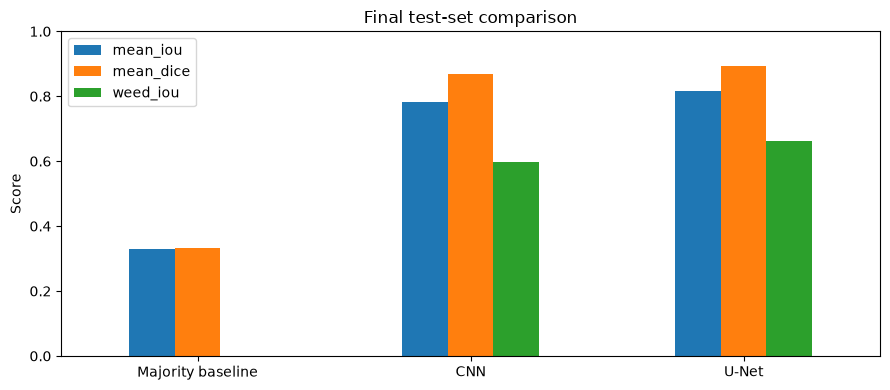

In [7]:
# 6.4 Test-set comparison table and chart
import pandas as pd
import matplotlib.pyplot as plt
FIGURE_DIR = ARTIFACT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
rows = []
for name, scores in results.items():
    row = dict(model=name, mean_iou=scores['mean_iou'],
               mean_dice=float(np.mean(scores['dice'])), weed_iou=scores['weed_iou'])
    for i, label in enumerate(['soil', 'crop', 'weed']):
        row[f'{label}_iou'] = scores['iou'][i]
        row[f'{label}_dice'] = scores['dice'][i]
    rows.append(row)
test_comparison = pd.DataFrame(rows)
display(test_comparison)
test_comparison.to_csv(ARTIFACT_DIR / 'MODEL_COMPARISON_TEST.csv', index=False)
ax = test_comparison.plot.bar(x='model', y=['mean_iou', 'mean_dice', 'weed_iou'],
                              figsize=(9, 4), rot=0, ylim=(0, 1))
ax.set(xlabel='', ylabel='Score', title='Final test-set comparison')
ax.figure.tight_layout()
ax.figure.savefig(FIGURE_DIR / 'model_comparison_test.png', dpi=150)
plt.show()
plt.close(ax.figure)


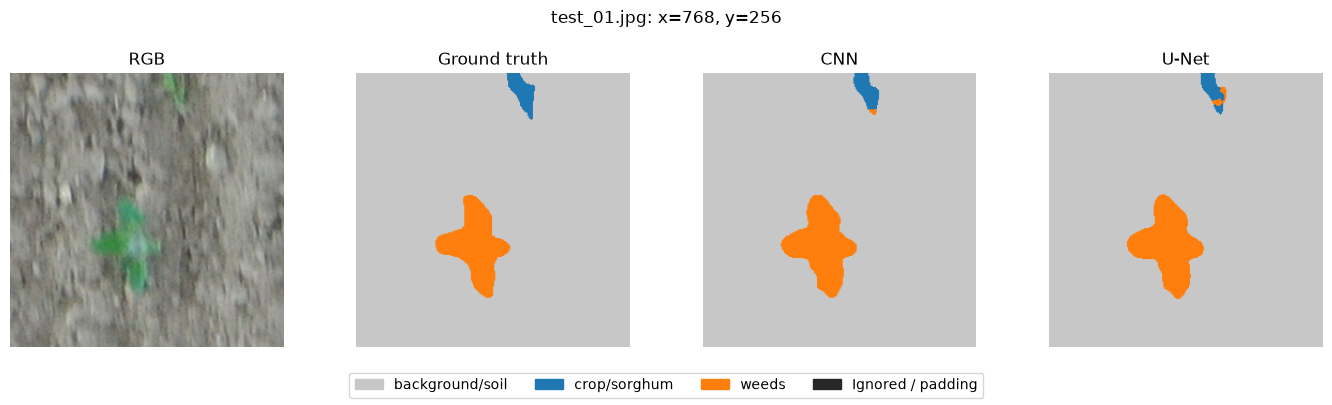

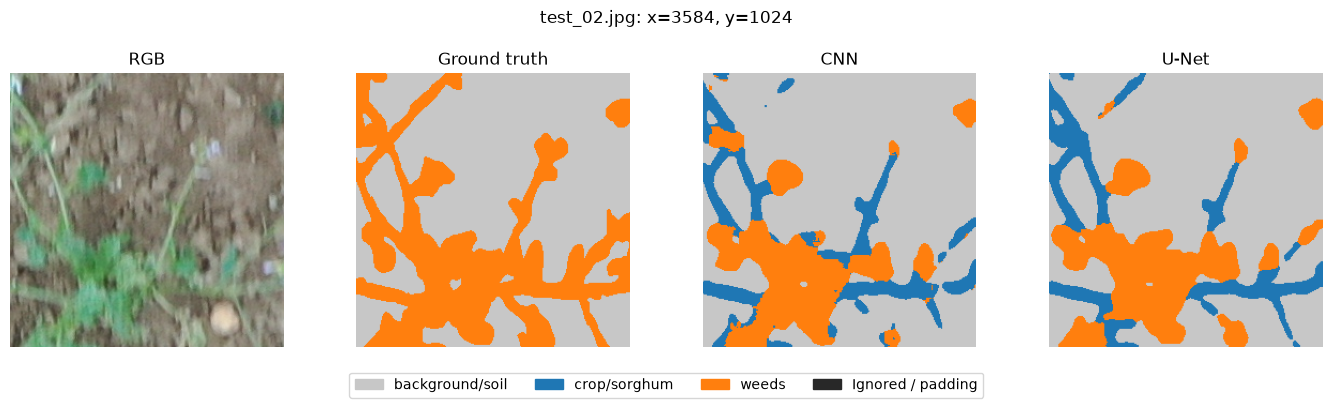

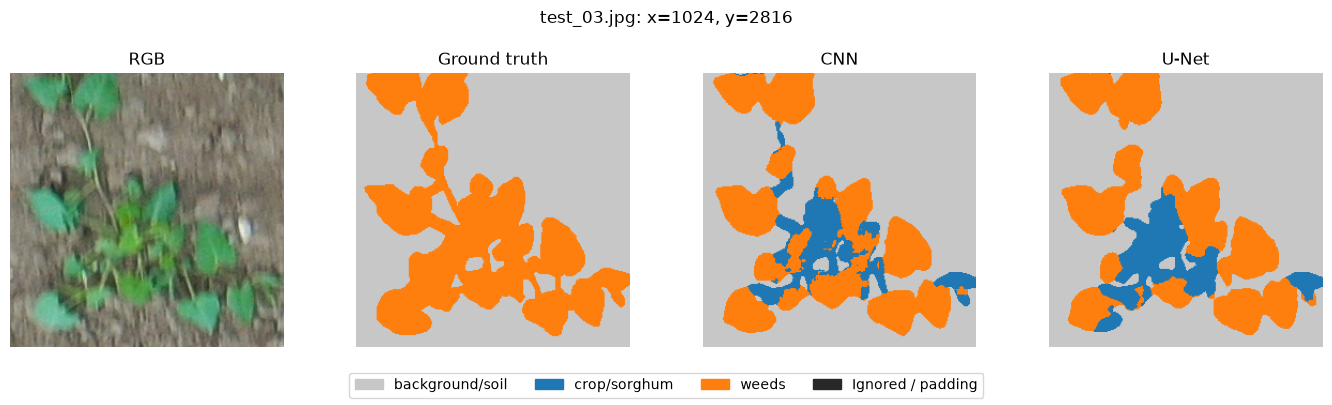

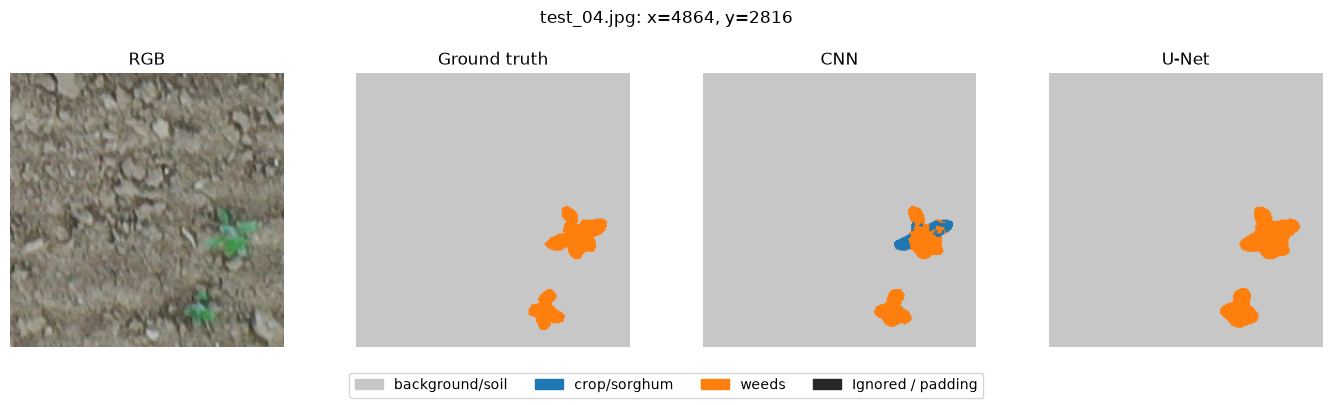

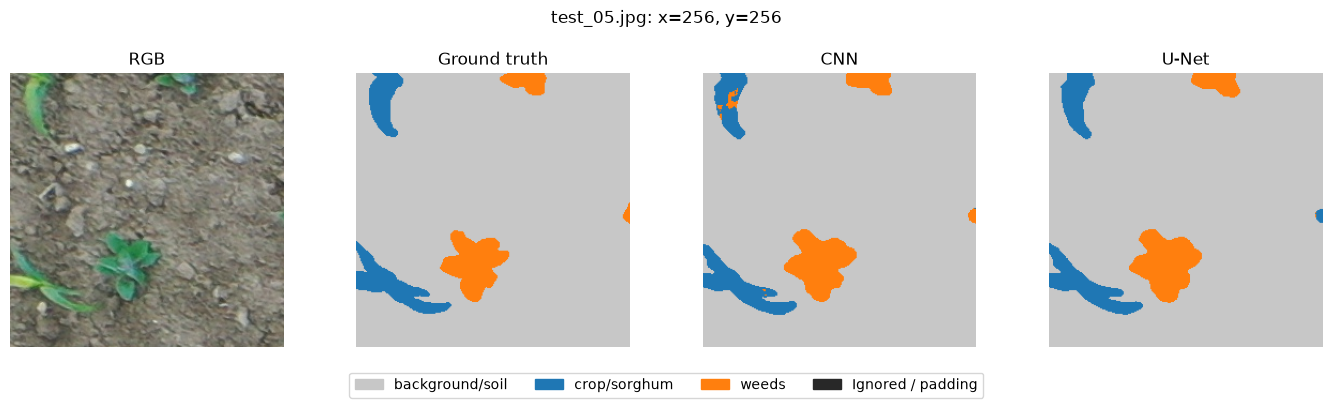

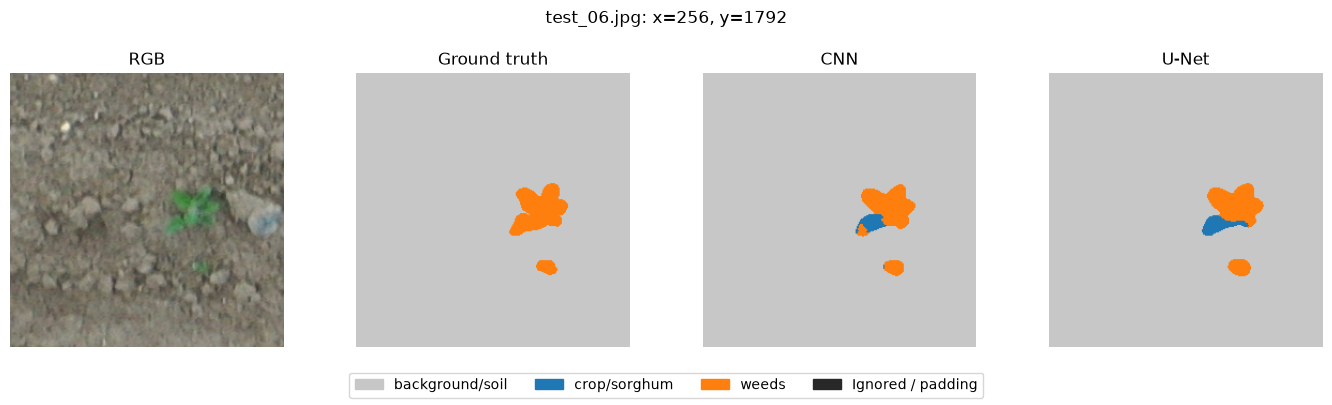

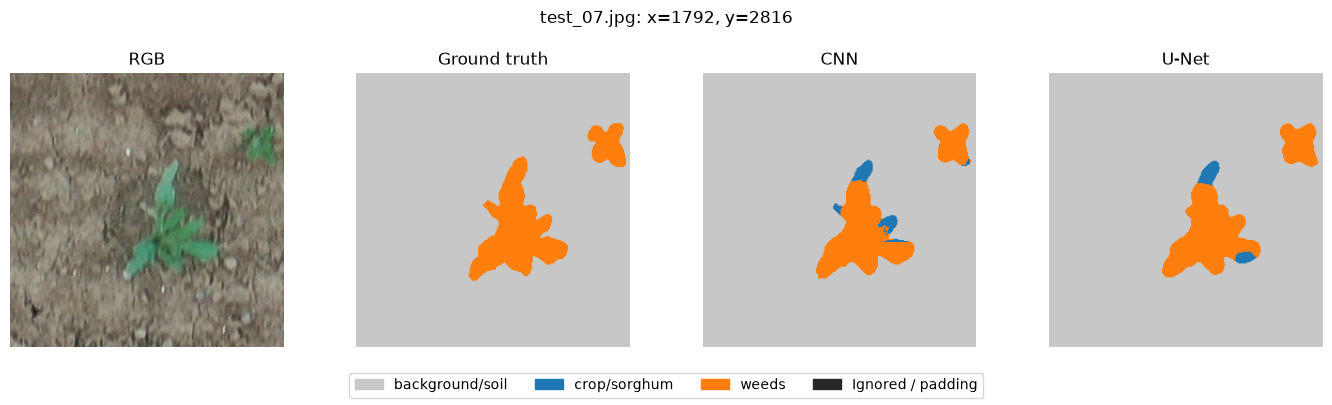

Saved figures: /Users/eva/Documents/Assignments/DATAX504/final-project/artifacts/figures


In [8]:
# 6.5 RGB / ground truth / CNN / U-Net prediction examples
# Select the patch with most ground-truth weed pixels per source image.
from matplotlib.patches import Patch
models = {name: tf.keras.models.load_model(ARTIFACT_DIR / filename, compile=False)
          for name, filename in [('CNN', 'small_encoder_decoder_best.keras'),
                                 ('U-Net', 'unet_best.keras')]}
ignore_color = np.array([40, 40, 40], dtype=np.uint8)
legend = [Patch(color=c / 255.0, label=n) for c, n in zip(CLASS_COLORS, CLASS_NAMES)]
legend.append(Patch(color=ignore_color / 255.0, label='Ignored / padding'))
def colorize(labels, valid):
    colors = CLASS_COLORS[labels].copy()
    colors[~valid] = ignore_color
    return colors

offset = 0
example_records = []
for path in test_images:
    with Image.open(path) as image:
        width, height = image.size
    columns = math.ceil(width / PATCH_SIZE)
    count = columns * math.ceil(height / PATCH_SIZE)
    labels, weights = (v[offset:offset + count] for v in test_arrays[1:])
    weed_counts = np.count_nonzero((labels == 2) & (weights > 0), axis=(1, 2))
    local_index = int(np.argmax(weed_counts))
    rgb, truth, weight = (v[offset + local_index] for v in test_arrays)
    valid = weight > 0
    panels = [('RGB', rgb), ('Ground truth', colorize(truth, valid))]
    for name, model in models.items():
        prediction = np.argmax(model(rgb[None], training=False).numpy()[0], axis=-1)
        panels.append((name, colorize(prediction, valid)))
    x, y = (local_index % columns) * PATCH_SIZE, (local_index // columns) * PATCH_SIZE
    fig, axes = plt.subplots(1, 4, figsize=(14, 4))
    for axis, (title, picture) in zip(axes, panels):
        axis.imshow(picture)
        axis.set_title(title)
        axis.axis('off')
    fig.suptitle(f'{path.name}: x={x}, y={y}')
    fig.legend(handles=legend, loc='lower center', ncol=4)
    fig.tight_layout(rect=(0, 0.10, 1, 0.94))
    fig.savefig(FIGURE_DIR / f'{path.stem}_prediction_comparison.png', dpi=150)
    plt.show()
    plt.close(fig)
    example_records.append(dict(image=str(path.relative_to(PROJECT_ROOT)),
                                x=x, y=y, weed_pixels=int(weed_counts[local_index])))
    offset += count
(ARTIFACT_DIR / 'PREDICTION_EXAMPLES.json').write_text(
    json.dumps(example_records, indent=2) + '\n', encoding='utf-8')
print('Saved figures:', FIGURE_DIR)
